# IEEE-CIS Fraud Detection: Testing Categorical Levels
## DSCI 598 Capstone, Week 5
### Ben Miller

Companion notebooks: `bm-fraud-categorical-tuning` and `bm-fraud-categorical-submission` (this week), and `bm-fraud-numeric-tuning` (Week 4).

# Part 1: Which levels of each categorical column are predictive?
> After submitting a model that uses only numerical features, explore adding categorical features. Use statistical tests to determine which levels of each categorical variable are most predictive. Keep only these levels and discard the rest.

This notebook runs the tests once, on the first 80% of the training data (the training part of the last fold), to show and explain what they find. The tuning notebook repeats them inside every fold.

### Decisions for this week

1. **Level selection rules.** A level is tested only if it has at least **500** training transactions. It's kept if it's still significant after a **Benjamini–Hochberg** correction at 5% across every level tested, its fraud rate is at least **1.5×** the overall rate or at most **0.67×** of it, and it ranks in its column's top **25** by chi-square statistic. Missing values count as their own level. Levels that aren't kept are grouped into one "other" column per categorical column, so no rows are lost.
2. **Selection is fit inside each fold.** Each cross-validation fold runs the tests on its own training rows only. If the tests used all the training data, each fold's validation rows would help choose the levels and the scores would look better than they really are.
3. **The same search as Week 4.** The same four time-ordered folds, metrics and number of settings per model (8, 12, 6 and 10), so any change in score comes from the categorical features.

### Imports, seeds and constants

In [1]:
import os
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Kaggle mounts the competition files here (read-only)
DATA_DIR = '/kaggle/input/competitions/ieee-fraud-detection'

# Column names used throughout
ID_COLUMN = 'TransactionID'
TARGET = 'isFraud'
TIME_COLUMN = 'TransactionDT'      # seconds from an undisclosed starting point, not a real timestamp
AMOUNT_COLUMN = 'TransactionAmt'

# Numerical features (the decision above): measurement-like columns only
NUMERIC_FAMILIES = ['C', 'D', 'V', 'dist']   # counts, time deltas, Vesta features, distances
NUMERIC_IDENTITY_COLUMNS = [f'id_{number:02d}' for number in range(1, 12)]  # id_01-id_11 are measurements; id_12 on are categories
OTHER_NUMERIC_COLUMNS = [AMOUNT_COLUMN, 'has_identity']

# V-column reduction
CORRELATION_SAMPLE_SIZE = 100_000   # rows used to measure correlations (feature selection only, not tuning)
HIGH_CORRELATION = 0.95             # V columns more correlated than this with one already kept are dropped

# Model settings that aren't tuned
TREE_MISSING_VALUE = -999      # scikit-learn trees get missing values replaced by this; it sits below every real value
LOGREG_MAX_ITER = 2000
LIGHTGBM_MAX_ROUNDS = 3000     # upper limit; early stopping picks the real number
EARLY_STOPPING_ROUNDS = 100

# Categorical level selection. These rules are fit on training rows only.
MIN_LEVEL_COUNT = 500        # levels with fewer training transactions aren't tested; their fraud rate is too noisy to trust
FDR_ALPHA = 0.05             # Benjamini-Hochberg false discovery rate across every level tested
MIN_RATE_RATIO = 1.5         # a kept level's fraud rate is at least 1.5x the overall rate, or at most 1/1.5 of it
MAX_LEVELS_PER_COLUMN = 25   # strongest levels kept per column, so no single column adds hundreds of features
MISSING_LABEL = 'missing'    # missing values are a level of their own, since a blank field can be a signal
OTHER_LABEL = 'other'        # every level that isn't kept is grouped here, so no rows are lost

N_FOLDS = 4                  # matches the tuning notebook; its last fold trains on the first 80% of the data
TOP_N_LEVELS_SHOWN = 15

sns.set_theme(style='whitegrid')

### Data-loading functions

In [2]:
def downcast_numeric_columns(frame):
    """
    Shrink float64 columns to float32 and integer columns to the smallest type that fits.
    The raw tables need several GB as float64; float32 roughly halves that, and tree
    models don't need the extra precision.
    """
    smaller_types = {}
    for column in frame.columns:
        if pd.api.types.is_float_dtype(frame[column]):
            smaller_types[column] = 'float32'
        elif pd.api.types.is_integer_dtype(frame[column]):
            smallest_fit = pd.to_numeric(frame[column], downcast='integer')
            smaller_types[column] = smallest_fit.dtype

    # one astype call for every column; assigning hundreds of columns one at a time fragments the DataFrame
    return frame.astype(smaller_types)


def standardize_identity_columns(identity):
    """
    Rename test_identity's 'id-01' style columns to train's 'id_01' spelling.
    The competition files use a hyphen in test and an underscore in train, so without
    this every identity feature would silently be missing in test after the merge.
    """
    renamed_columns = {}
    for column in identity.columns:
        if column.startswith('id-'):
            renamed_columns[column] = column.replace('id-', 'id_')
    return identity.rename(columns=renamed_columns)


def load_table(file_name):
    """One competition CSV, with its numeric columns downcast."""
    frame = pd.read_csv(os.path.join(DATA_DIR, file_name))
    return downcast_numeric_columns(frame)


def merge_identity(transactions, identity):
    """
    Left-join identity onto transactions by TransactionID, and flag which rows had a match.
    Only some transactions have identity data, so a left join keeps every transaction and
    leaves the identity columns missing for the rest.
    """
    # mark identity rows before the merge; transactions without a match end up missing, then 0
    flagged_identity = identity.assign(has_identity=1)
    merged = transactions.merge(flagged_identity, on=ID_COLUMN, how='left')
    merged['has_identity'] = merged['has_identity'].fillna(0).astype('int8')
    return merged


def load_split(split_name):
    """The merged transaction + identity table for 'train' or 'test'."""
    transactions = load_table(f'{split_name}_transaction.csv')
    identity = standardize_identity_columns(load_table(f'{split_name}_identity.csv'))
    return merge_identity(transactions, identity)


def memory_mb(frame):
    """How much memory a DataFrame uses, in megabytes."""
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

### Load train and test

Train is sorted by time, as in Week 4. Test is only used to check how well the kept levels carry over to later transactions.

In [3]:
train = load_split('train')
train = train.sort_values(TIME_COLUMN).reset_index(drop=True)
test = load_split('test')
print(f'train: {train.shape[0]:,} rows, test: {test.shape[0]:,} rows')

train: 590,540 rows, test: 506,691 rows


### Feature functions (from Week 4)

In [4]:
def column_family(column):
    """The feature family a column belongs to, from its name: 'V' for V1-V339, 'dist' for dist1-dist2, and so on."""
    if column.startswith('id_'):
        return 'id'
    return column.rstrip('0123456789')  # 'V258' -> 'V', 'dist1' -> 'dist'


def numeric_feature_columns(frame):
    """
    The measurement-like columns: amount, the identity flag, C, D, V, dist and id_01-id_11.
    Columns that hold category codes stored as numbers (card1-card6, addr1, addr2, id_12 on)
    are left out on purpose, along with the text columns.
    """
    features = []
    for column in frame.columns:
        if column_family(column) in NUMERIC_FAMILIES:
            features.append(column)
        elif column in NUMERIC_IDENTITY_COLUMNS or column in OTHER_NUMERIC_COLUMNS:
            features.append(column)
    return features


def select_uncorrelated_columns(frame, columns, threshold, sample_size):
    """
    Keep one column from each group of near-duplicates, scanning the columns in order.
    A column is dropped when its absolute correlation with a column already kept is above threshold.
    Correlations come from a random sample of rows: plenty to measure a correlation, and much faster than all rows.
    """
    sample = frame[columns].sample(n=min(sample_size, len(frame)), random_state=SEED)
    correlation = sample.corr().abs()
    kept_columns = []
    for column in columns:
        is_near_duplicate = False
        for kept_column in kept_columns:
            if correlation.loc[column, kept_column] > threshold:
                is_near_duplicate = True
                break
        if not is_near_duplicate:
            kept_columns.append(column)
    return kept_columns


def model_feature_columns(frame):
    """The numerical features with redundant V columns removed."""
    numeric_columns = numeric_feature_columns(frame)
    v_columns = []
    other_columns = []
    for column in numeric_columns:
        if column_family(column) == 'V':
            v_columns.append(column)
        else:
            other_columns.append(column)
    kept_v_columns = select_uncorrelated_columns(frame, v_columns, HIGH_CORRELATION, CORRELATION_SAMPLE_SIZE)
    return other_columns + kept_v_columns

### Categorical level functions

Label each categorical column, test every level that has enough rows, and decide which levels to keep.

In [5]:
def categorical_feature_columns(frame, numeric_columns):
    """Every column that isn't numerical, the ID, the target or the raw time: the columns held back in Week 4."""
    excluded = set(numeric_columns) | {ID_COLUMN, TARGET, TIME_COLUMN}
    categorical_columns = []
    for column in frame.columns:
        if column not in excluded:
            categorical_columns.append(column)
    return categorical_columns


def categorical_labels(series):
    """
    One categorical column as text labels, with missing values labeled 'missing'.
    Number codes are converted to float first, so a code reads the same in train and test
    (1234.0 in both, not 1234 in one file and 1234.0 in the other).
    """
    is_missing = series.isna()
    if pd.api.types.is_numeric_dtype(series):
        series = series.astype('float64')
    labels = series.astype(str)
    labels[is_missing] = MISSING_LABEL
    return labels.astype('category')


def categorical_label_frame(frame, categorical_columns):
    """
    Text labels for every categorical column, built once up front.
    This step doesn't look at the target, so building it on all rows can't leak anything.
    """
    labels = {}
    for column in categorical_columns:
        labels[column] = categorical_labels(frame[column])
    return pd.DataFrame(labels, index=frame.index)


def test_levels(labels, target):
    """
    A chi-square test for every level of one column that has at least MIN_LEVEL_COUNT rows.
    Each test uses a 2x2 table (in this level or not, fraud or not) to ask whether the level's
    fraud rate differs from the rate in all the other rows.
    """
    target = np.asarray(target).astype('int64')   # isFraud is stored as int8, which would overflow in the counts below
    total_rows = len(target)
    total_fraud = int(target.sum())
    overall_rate = total_fraud / total_rows
    level_rows = labels.value_counts()
    level_fraud = pd.Series(target, index=labels.index).groupby(labels, observed=True).sum()

    rows = []
    for level, rows_in_level in level_rows.items():
        rows_in_level = int(rows_in_level)
        if rows_in_level < MIN_LEVEL_COUNT or rows_in_level == total_rows:
            continue  # too rare to trust, or the column has only one level here, so there's nothing to compare
        fraud_in_level = int(level_fraud[level])
        table = [
            [fraud_in_level, rows_in_level - fraud_in_level],
            [total_fraud - fraud_in_level, (total_rows - rows_in_level) - (total_fraud - fraud_in_level)],
        ]
        chi_square, p_value, _, _ = chi2_contingency(table)
        level_rate = fraud_in_level / rows_in_level
        rows.append({
            'level': level,
            'transactions': int(rows_in_level),
            'fraud_rate': level_rate,
            'rate_ratio': level_rate / overall_rate,
            'chi_square': chi_square,
            'p_value': p_value,
        })
    return pd.DataFrame(rows)


def find_predictive_levels(label_frame, target):
    """
    Test every level of every categorical column, then mark which levels to keep. A level is kept when it
    (1) is still significant after the Benjamini-Hochberg correction across all tests,
    (2) has a fraud rate at least MIN_RATE_RATIO times the overall rate, or at most 1/MIN_RATE_RATIO of it, and
    (3) ranks in its column's top MAX_LEVELS_PER_COLUMN by chi-square statistic.
    Returns one row per level tested.
    """
    column_reports = []
    for column in label_frame.columns:
        column_report = test_levels(label_frame[column], target)
        if len(column_report) > 0:
            column_report.insert(0, 'column', column)
            column_reports.append(column_report)
    if not column_reports:
        return pd.DataFrame(columns=['column', 'level', 'transactions', 'fraud_rate', 'rate_ratio',
                                     'chi_square', 'p_value', 'adjusted_p_value', 'kept'])

    report = pd.concat(column_reports, ignore_index=True)
    significant, adjusted_p_values, _, _ = multipletests(report['p_value'], alpha=FDR_ALPHA, method='fdr_bh')
    report['adjusted_p_value'] = adjusted_p_values
    report['significant'] = significant

    much_higher = report['rate_ratio'] >= MIN_RATE_RATIO
    much_lower = report['rate_ratio'] <= 1 / MIN_RATE_RATIO
    report['large_difference'] = much_higher | much_lower
    report['passes'] = report['significant'] & report['large_difference']

    # rank only the passing levels within each column; the rest get no rank and aren't kept
    passing = report[report['passes']]
    report['rank_in_column'] = passing.groupby('column')['chi_square'].rank(ascending=False, method='first')
    report['kept'] = report['passes'] & (report['rank_in_column'] <= MAX_LEVELS_PER_COLUMN)
    return report


def kept_levels_by_column(report):
    """The kept levels, grouped by column: {'ProductCD': ['C', 'W'], ...}."""
    kept_levels = {}
    kept_rows = report[report['kept']]
    for column, level in zip(kept_rows['column'], kept_rows['level']):
        if column not in kept_levels:
            kept_levels[column] = []
        kept_levels[column].append(level)
    return kept_levels


def safe_feature_name(text):
    """
    A column name LightGBM accepts. It rejects some punctuation in feature names, and level values like
    device names can contain it, so anything that isn't a letter, digit, dot or dash becomes an underscore.
    """
    characters = []
    for character in text:
        if character.isalnum() or character in '.-':
            characters.append(character)
        else:
            characters.append('_')
    return ''.join(characters)


def level_indicator_columns(label_frame, kept_levels):
    """
    A 0/1 column for each kept level, plus one 'other' column per categorical column for every level that
    wasn't kept. Columns with no kept levels are left out entirely.
    """
    indicators = {}
    for column, levels in kept_levels.items():
        labels = label_frame[column]
        in_a_kept_level = np.zeros(len(labels), dtype=bool)
        for level in levels:
            is_level = (labels == level).to_numpy()
            name = safe_feature_name(f'{column}__{level}')
            if name in indicators:
                name = f'{name}_{len(indicators)}'   # two levels that differ only in punctuation would otherwise share a name
            indicators[name] = is_level
            in_a_kept_level = in_a_kept_level | is_level
        indicators[safe_feature_name(f'{column}__{OTHER_LABEL}')] = np.logical_not(in_a_kept_level)
    return pd.DataFrame(indicators, index=label_frame.index).astype('float32')


def build_model_matrix(numeric_frame, label_frame, kept_levels):
    """The numerical features followed by the level indicator columns, all as float32."""
    indicators = level_indicator_columns(label_frame, kept_levels)
    return pd.concat([numeric_frame.astype('float32'), indicators], axis=1)

### The categorical columns and how many levels each has

The number of distinct values decides how much the minimum-count rule matters: columns with thousands of values have most of their levels screened out for being too rare.

In [6]:
numeric_columns = numeric_feature_columns(train)
categorical_columns = categorical_feature_columns(train, numeric_columns)
train_labels = categorical_label_frame(train, categorical_columns)


def level_summary(label_frame):
    """Per column: distinct levels, levels with at least MIN_LEVEL_COUNT rows, and the share of rows that are missing."""
    rows = []
    for column in label_frame.columns:
        counts = label_frame[column].value_counts()
        rows.append({
            'column': column,
            'distinct_levels': int((counts > 0).sum()),
            f'levels_with_{MIN_LEVEL_COUNT}_rows': int((counts >= MIN_LEVEL_COUNT).sum()),
            'missing_share': (label_frame[column] == MISSING_LABEL).mean(),
        })
    return pd.DataFrame(rows).sort_values('distinct_levels', ascending=False).reset_index(drop=True)


summary = level_summary(train_labels)
print(f'{len(categorical_columns)} categorical columns')
print(summary.round(3).to_string(index=False))

49 categorical columns
       column  distinct_levels  levels_with_500_rows  missing_share
        card1            13553                   199          0.000
   DeviceInfo             1787                     8          0.799
        id_19              523                    37          0.764
        card2              501                   108          0.015
        id_21              491                     2          0.991
        id_20              395                    47          0.764
        id_25              342                     2          0.991
        addr1              333                    55          0.111
        id_33              261                    21          0.876
        id_31              131                    32          0.762
        card5              120                    23          0.007
        card3              115                     9          0.003
        id_17              105                     4          0.764
        id_26            

### Run the tests on the first 80% of training data

These are the same rows the last fold of the tuning notebook trains on.

In [7]:
n_rows = len(train)
last_fold_train_rows = n_rows - n_rows // (N_FOLDS + 1)   # TimeSeriesSplit's last fold trains on everything before its final slice
first_80_labels = train_labels.iloc[:last_fold_train_rows]
first_80_target = train[TARGET].to_numpy()[:last_fold_train_rows]

report = find_predictive_levels(first_80_labels, first_80_target)
kept_levels = kept_levels_by_column(report)
print(f'tested on {last_fold_train_rows:,} rows (overall fraud rate {first_80_target.mean():.2%})')
print(f"{len(report):,} levels tested, {int(report['significant'].sum()):,} significant after correction, "
      f"{int(report['passes'].sum()):,} also have a large difference, {int(report['kept'].sum()):,} kept")
print(f'{len(kept_levels)} of {len(categorical_columns)} columns keep at least one level')

tested on 472,432 rows (overall fraud rate 3.51%)
665 levels tested, 540 significant after correction, 436 also have a large difference, 301 kept
47 of 49 columns keep at least one level


### Results by column

In [8]:
def selection_by_column(report):
    """Per column: levels tested, significant, passing both rules, and kept."""
    grouped = report.groupby('column')
    summary = pd.DataFrame({
        'tested': grouped.size(),
        'significant': grouped['significant'].sum(),
        'passes_both_rules': grouped['passes'].sum(),
        'kept': grouped['kept'].sum(),
    })
    return summary.sort_values('kept', ascending=False)


print(selection_by_column(report).to_string())

               tested  significant  passes_both_rules  kept
column                                                     
addr1              54           41                 26    25
card1             161          118                109    25
id_19              35           30                 25    25
id_20              44           31                 29    25
card2              97           82                 71    25
id_31              28           24                 22    22
id_30              24           19                 16    16
card5              23           19                 15    15
P_emaildomain      23           18                 14    14
id_33              20           16                 13    13
id_13              14           13                 12    12
R_emaildomain      14           11                 10    10
card3               9            7                  6     6
DeviceInfo          7            6                  5     5
id_18               5            5      

### The strongest levels

Kept levels with the highest and lowest fraud rates compared with the overall rate. A rate ratio of 3.0 means the level's fraud rate is three times the overall rate.

Highest fraud rates among kept levels:
column   level  transactions  fraud_rate  rate_ratio  adjusted_p_value
 card1  9917.0           749      0.3805     10.8298               0.0
 id_19   384.0           949      0.3224      9.1773               0.0
 id_13    43.0           836      0.2907      8.2729               0.0
 card1 14276.0           741      0.2848      8.1044               0.0
 card2   142.0          1373      0.2658      7.5662               0.0
 card2   177.0          1387      0.2401      6.8332               0.0
 card2   104.0           664      0.2395      6.8153               0.0
 card1 10876.0           662      0.2387      6.7929               0.0
 card1  4504.0           848      0.2347      6.6790               0.0
 card2   130.0          1984      0.2288      6.5129               0.0
 id_20   561.0          1433      0.2254      6.4153               0.0
 id_19   484.0           790      0.2241      6.3768               0.0
 id_20   612.0           713      0.21

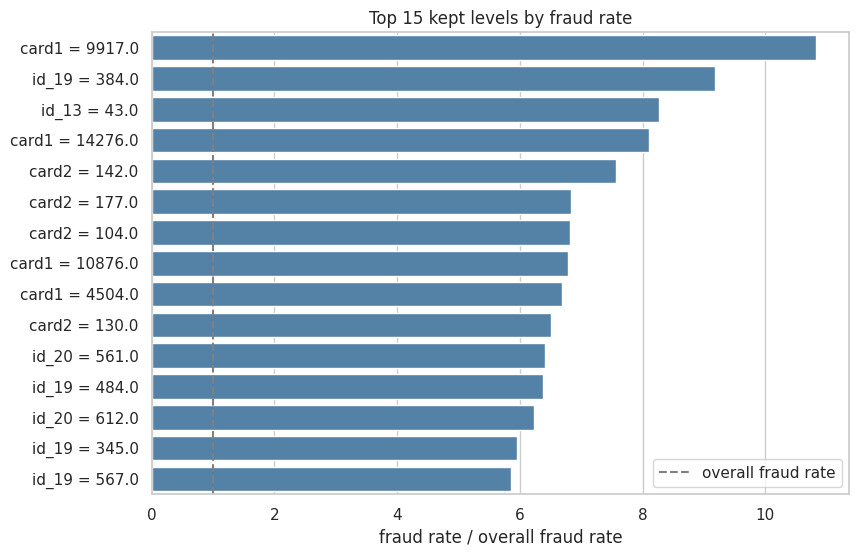

In [9]:
kept_report = report[report['kept']]
display_columns = ['column', 'level', 'transactions', 'fraud_rate', 'rate_ratio', 'adjusted_p_value']

riskiest = kept_report.sort_values('rate_ratio', ascending=False).head(TOP_N_LEVELS_SHOWN)
safest = kept_report.sort_values('rate_ratio').head(TOP_N_LEVELS_SHOWN)
print('Highest fraud rates among kept levels:')
print(riskiest[display_columns].round(4).to_string(index=False))
print('\nLowest fraud rates among kept levels:')
print(safest[display_columns].round(4).to_string(index=False))

riskiest_plot = riskiest.assign(name=riskiest['column'] + ' = ' + riskiest['level'].astype(str))
plt.figure(figsize=(9, 6))
sns.barplot(x='rate_ratio', y='name', data=riskiest_plot, color='steelblue')
plt.axvline(1.0, linestyle='--', color='gray', label='overall fraud rate')
plt.xlabel('fraud rate / overall fraud rate')
plt.ylabel('')
plt.title(f'Top {TOP_N_LEVELS_SHOWN} kept levels by fraud rate')
plt.legend()
plt.show()

### Do the kept levels carry over to test?

Test comes after train in time. If most test transactions fall into "other" for a column, that column's kept levels may not generalize well. This only uses test's column values, never its labels.

In [10]:
def share_in_kept_levels(label_frame, kept_levels):
    """For each column with kept levels, the share of rows that fall into one of them."""
    shares = {}
    for column, levels in kept_levels.items():
        shares[column] = label_frame[column].isin(levels).mean()
    return pd.Series(shares)


test_labels = categorical_label_frame(test, categorical_columns)
coverage = pd.DataFrame({
    'train_first_80pct': share_in_kept_levels(first_80_labels, kept_levels),
    'test': share_in_kept_levels(test_labels, kept_levels),
})
coverage['change'] = coverage['test'] - coverage['train_first_80pct']
print(coverage.sort_values('change').round(3).to_string())

               train_first_80pct   test  change
id_31                      0.954  0.766  -0.188
id_13                      0.990  0.858  -0.132
id_34                      0.033  0.000  -0.033
id_30                      0.045  0.018  -0.027
card6                      0.258  0.234  -0.023
id_19                      0.894  0.881  -0.013
id_20                      0.891  0.878  -0.013
card5                      0.314  0.303  -0.011
card1                      0.103  0.095  -0.007
id_32                      0.046  0.039  -0.007
P_emaildomain              0.329  0.323  -0.006
card4                      0.011  0.006  -0.006
id_28                      0.884  0.879  -0.004
id_29                      0.881  0.877  -0.004
id_33                      0.070  0.067  -0.003
R_emaildomain              0.942  0.940  -0.003
id_16                      0.886  0.883  -0.002
id_15                      0.888  0.886  -0.002
id_21                      0.004  0.002  -0.002
id_17                      0.852  0.850 

### What the tests showed

- **665** levels tested across **49** columns; **301** kept from **47** columns. 540 levels were still significant after the Benjamini–Hochberg correction, and 436 of those also had a fraud rate at least 1.5× or at most 0.67× the overall rate of 3.51%. The top-25 cap then trimmed `card1`, `card2`, `addr1` and `id_20`.
- Riskiest kept levels: specific `card1` and `card2` codes and `id_19`/`id_20` values. `card1` 9917 has a 38% fraud rate, about 11 times the overall rate, and all of the top 15 are above 20%.
- Lowest-risk kept levels: email domains like verizon.net, msn.com, sbcglobal.net and att.net, plus the IE 11 for tablet browser, all with fraud rates under 0.7%. verizon.net had no fraud at all in 552 transactions.
- Carry-over to test: for most columns, the kept levels cover about the same share of test transactions as the first 80% of train (within 3 points). The biggest drops are `id_31` (95% to 77%) and `id_13` (99% to 86%). `id_31` is the browser, so this is probably newer browser versions showing up in test and falling into "other". The M columns go the other way, with their kept levels covering 14–17 points more of test.